# Intermediate thermodynamics

A binary mixture of methane and n-butane, flashed with a Peng-Robinson equation of state:
a TP flash, the vapour fraction across a temperature range, the P-T phase envelope, and
enthalpy and transport properties at the flash roots.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import azoth
import azoth.eos
from azoth.core.result import Phase
from azoth.eos.components import mixture_of

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.alpha": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2.0,
        "font.size": 9,
        "figure.figsize": (6.4, 3.4),
    }
)

q = azoth.ureg.Quantity

## The mixture

`mixture_of` returns the `Mixture` and the ideal-gas model the enthalpy calculation needs.
The molar mass is on each component; the mixture has no single molar-mass property.

In [2]:
mix, ideal = mixture_of(["methane", "n-butane"])
z = [0.9, 0.1]

for component in mix.components:
    print(
        f"M = {component.molar_mass.to('g/mol').magnitude:.3f} g/mol  "
        f"Tc = {component.Tc.to('K').magnitude:.2f} K  "
        f"Pc = {component.Pc.to('bar').magnitude:.1f} bar"
    )

M = 16.043 g/mol  Tc = 190.56 K  Pc = 46.0 bar
M = 58.123 g/mol  Tc = 425.12 K  Pc = 38.0 bar


## A TP flash

`pt_flash` converges K-values by successive substitution. Read `phase` before
`vapour_fraction`: outside a two-phase split the vapour fraction is the *negative-flash* value
and can lie outside `[0, 1]`, while `phase` says what the state actually is.

In [3]:
T, P = q(250.0, "K"), q(20.0, "bar")
flash = azoth.eos.pt_flash(mix, T, P, z)

print("phase:", flash.phase)
print("vapour fraction:", flash.vapour_fraction)
print("x:", flash.x)
print("y:", flash.y)
print("K:", flash.k)
print("iterations:", flash.iterations, "residual:", flash.residual)

phase: two_phase
vapour fraction: 0.9128573723989127
x: (0.1555272121730027, 0.8444727878270136)
y: (0.9710684022173852, 0.028931597782613196)
K: (6.243720238084155, 0.03425995271802613)
iterations: 10 residual: 2.1896782287804767e-11


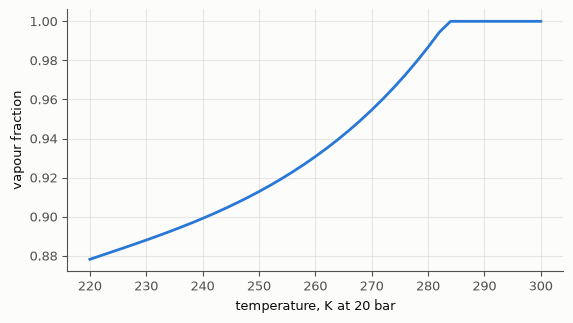

In [4]:
def vapour_fraction(temperature: float) -> float:
    result = azoth.eos.pt_flash(mix, q(temperature, "K"), P, z)
    if result.phase is Phase.ALL_LIQUID:
        return 0.0
    if result.phase is Phase.ALL_VAPOUR:
        return 1.0
    return result.vapour_fraction


temperatures = np.linspace(220.0, 300.0, 41)
fig, ax = plt.subplots()
ax.plot(temperatures, [vapour_fraction(float(t)) for t in temperatures], color=PALETTE[0])
ax.set_xlabel("temperature, K at 20 bar")
ax.set_ylabel("vapour fraction")
plt.show()
plt.close(fig)

## The phase envelope

`pt_phase_envelope` traces the dew and bubble branches upward from the starting pressure. The
two branches are parallel tuples of temperatures and pressures. The trace stops at the
cricondenbar and near the critical point; the dotted segments in the plot close the loop.

In [5]:
envelope = azoth.eos.pt_phase_envelope(mix, q(1.0, "bar"), z)
print("critical:", envelope.critical_temperature, envelope.critical_pressure)
print("cricondenbar:", envelope.cricondenbar_temperature, envelope.cricondenbar_pressure)
print("cricondentherm:", envelope.cricondentherm_temperature, envelope.cricondentherm_pressure)

critical: 231.68637206865841 kelvin 10193937.700145101 pascal
cricondenbar: 266.1077530490633 kelvin 12391408.71826942 pascal
cricondentherm: 301.6014896386178 kelvin 6447123.474765686 pascal


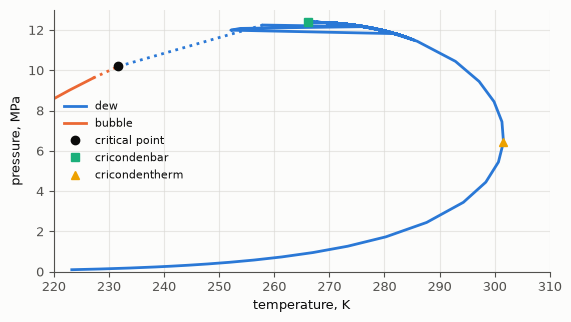

In [6]:
critical_t = envelope.critical_temperature.to("K").magnitude
critical_p = envelope.critical_pressure.to("MPa").magnitude
dew_t = [t.to("K").magnitude for t in envelope.dew_temperature]
dew_p = [p.to("MPa").magnitude for p in envelope.dew_pressure]
bubble_t = [t.to("K").magnitude for t in envelope.bubble_temperature]
bubble_p = [p.to("MPa").magnitude for p in envelope.bubble_pressure]

fig, ax = plt.subplots()
ax.plot(dew_t, dew_p, color=PALETTE[0], label="dew")
ax.plot(bubble_t, bubble_p, color=PALETTE[1], label="bubble")
# The trace stops at the cricondenbar and near the critical point; the dotted segments
# close the loop rather than pretend the trace reached where it did not.
ax.plot([dew_t[-1], critical_t], [dew_p[-1], critical_p], ":", color=PALETTE[0])
ax.plot([bubble_t[-1], critical_t], [bubble_p[-1], critical_p], ":", color=PALETTE[1])
ax.plot(critical_t, critical_p, "o", color=INK, label="critical point")
ax.plot(
    envelope.cricondenbar_temperature.to("K").magnitude,
    envelope.cricondenbar_pressure.to("MPa").magnitude,
    "s",
    color=PALETTE[2],
    label="cricondenbar",
)
ax.plot(
    envelope.cricondentherm_temperature.to("K").magnitude,
    envelope.cricondentherm_pressure.to("MPa").magnitude,
    "^",
    color=PALETTE[3],
    label="cricondentherm",
)
ax.set_xlabel("temperature, K")
ax.set_ylabel("pressure, MPa")
ax.set_xlim(220, 310)
ax.set_ylim(0, 13)
ax.legend(frameon=False, fontsize=8)
plt.show()
plt.close(fig)

## A pure component's saturation pressure

`pure_saturation` is the same cubic's vapour-pressure curve for one component, at the
critical constants the databank holds.

In [7]:
methane = azoth.eos.component("methane")
saturation = azoth.eos.pure_saturation(methane.Tc, methane.Pc, methane.omega, q(150.0, "K"))
print("methane vapour pressure at 150 K:", saturation.p_sat.to("bar"))
print("iterations:", saturation.iterations)

methane vapour pressure at 150 K: 10.471626681121922 bar
iterations: 42


## Enthalpy at the two roots

The same state has a liquid and a vapour root. `molar_enthalpy_entropy` takes the composition
and the compressibility root the flash selected, and returns h, s, cp and their departures
from the ideal gas.

In [8]:
liquid = azoth.eos.molar_enthalpy_entropy(mix, ideal, T, P, list(flash.x), flash.z_liquid)
vapour = azoth.eos.molar_enthalpy_entropy(mix, ideal, T, P, list(flash.y), flash.z_vapour)

print(f"liquid h: {liquid.h.to('kJ/mol').magnitude:.3f} kJ/mol")
print(f"liquid cp: {liquid.cp.to('J/(mol*K)').magnitude:.1f} J/(mol*K)")
print(f"vapour h: {vapour.h.to('kJ/mol').magnitude:.3f} kJ/mol")
print(f"vapour cp: {vapour.cp.to('J/(mol*K)').magnitude:.1f} J/(mol*K)")
print(f"latent heat: {(vapour.h - liquid.h).to('kJ/mol').magnitude:.3f} kJ/mol")

liquid h: -22.425 kJ/mol
liquid cp: 114.5 J/(mol*K)
vapour h: -1.394 kJ/mol
vapour cp: 39.5 J/(mol*K)
latent heat: 21.031 kJ/mol


## Transport properties

The liquid correlation is a corresponding-states form over the liquid root; pass the liquid
composition and the state it applies at.

In [9]:
viscosity = azoth.eos.viscosity(mix, T, P, list(flash.x))
conductivity = azoth.eos.thermal_conductivity(mix, ideal, T, P, list(flash.x))

print(f"liquid viscosity: {viscosity.mu.to('mPa*s').magnitude:.3f} mPa*s")
print(f"liquid conductivity: {conductivity.k.to('W/(m*K)').magnitude:.3f} W/(m*K)")
print("warnings:", [warning.code.value for warning in viscosity.warnings + conductivity.warnings])

liquid viscosity: 0.211 mPa*s
liquid conductivity: 0.115 W/(m*K)
warnings: []


## Provenance and warnings

The flash says which source it is attributed to and how far it is externally checked. A
warning here is a caveat on the value, not a failure.

In [10]:
print("verification:", flash.provenance.verification)
print("source:", flash.provenance.source)
print("skipped checks:", flash.provenance.skipped_checks)
print("warnings:", [warning.code.value for warning in flash.warnings])

verification: partially_verified
source: Rachford, H. H.; Rice, J. D. (1952); Michelsen, M. L. (1982)
skipped checks: ()
warnings: []


## Next

- [Python scripting and Jupyter](https://patrickmockridge.github.io/azoth/manual/using/python.html)
- The generated pages for [`pt_flash`](https://patrickmockridge.github.io/azoth/manual/eos/pt_flash.html)
  and [`pt_phase_envelope`](https://patrickmockridge.github.io/azoth/manual/eos/pt_phase_envelope.html).